<a href="https://colab.research.google.com/github/mawardi-IF/ilp-hazard-kelompok-2/blob/main/war_simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ILP Simulator - Implementasi WAR (Write After Read)

Jalankan sel di bawah (Runtime → Run all). Dependency graph akan tampil di bawah output dan tersimpan sebagai PNG di panel Files.



************************************************************
   INSTRUCTION-LEVEL PARALLELISM SIMULATOR - WAR
************************************************************

Instruction Set:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R2 = R7 + R8
I4: R5 = R9 + R10
I5: R9 = R11 + R12
I6: R13 = R14 + R15

DEPENDENCY ANALYSIS - WAR (Write After Read)
I3 depends on I1 (WAR, Register: R2) -> I3 menulis R2 yang dibaca I1
I4 depends on I2 (WAR, Register: R5) -> I4 menulis R5 yang dibaca I2
I5 depends on I4 (WAR, Register: R9) -> I5 menulis R9 yang dibaca I4

SEQUENTIAL EXECUTION
Cycle 1: Executing I1 (R1 = R2 + R3)
Cycle 2: Executing I2 (R4 = R5 + R6)
Cycle 3: Executing I3 (R2 = R7 + R8)
Cycle 4: Executing I4 (R5 = R9 + R10)
Cycle 5: Executing I5 (R9 = R11 + R12)
Cycle 6: Executing I6 (R13 = R14 + R15)

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION (WAR)

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I2: R4 = R5 + R6
  -> I6: R13 = R14 + R15

Cycle 2:
  -> I3: R2 = R7 + R8
  -> I4: R5 = R

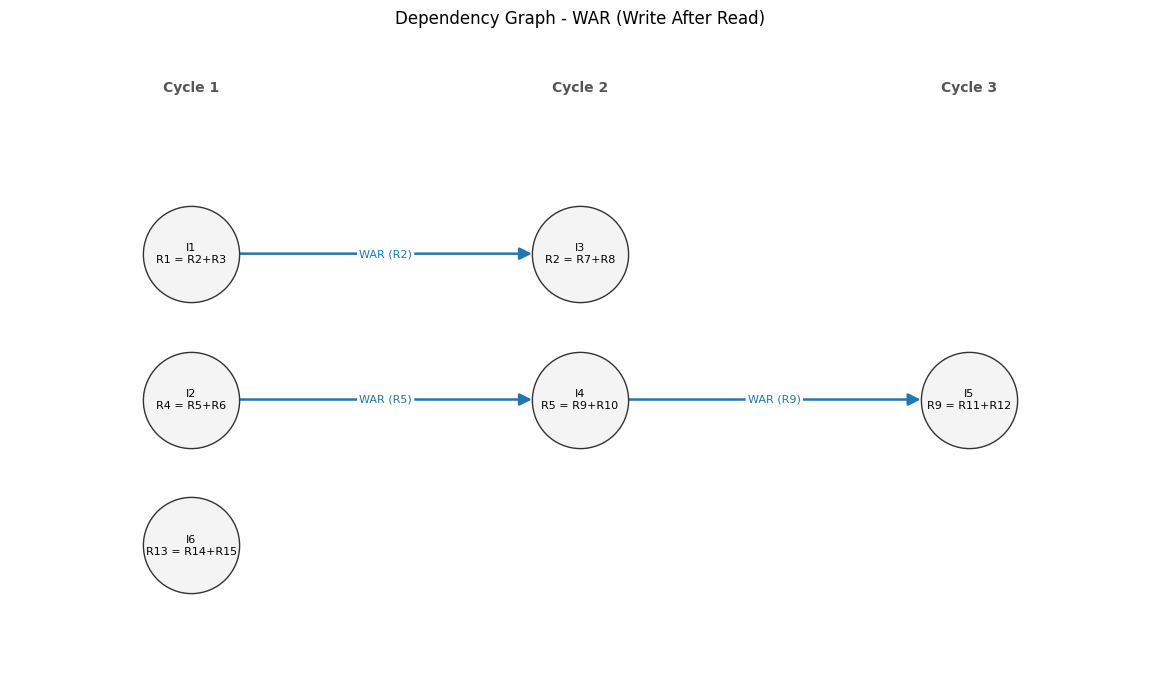

Dependency graph disimpan: dependency_graph_war.png


In [ ]:
# =================================================================
# ILP SIMULATOR - IMPLEMENTASI DEPENDENSI WAR (Write After Read)
# Simulator asal: https://github.com/harshitasingh4863/instruction-level-parallelism-simulator.git
# =================================================================
#
# WAR (Write After Read) = Anti Dependency
#   Terjadi jika instruksi j MENULIS register yang DIBACA oleh
#   instruksi i yang datang lebih dulu (i < j).
#   Instruksi j tidak boleh menulis sebelum i selesai membaca,
#   karena i akan membaca nilai baru yang salah.
#
#   Contoh:  I1: R1 = R2 + R3
#            I3: R2 = R7 + R8   <- I3 menimpa R2 yang dibaca I1
#
#   WAR adalah "name dependency": tidak ada aliran data antar
#   instruksi, hanya pemakaian nama register yang sama. Bisa
#   dihilangkan dengan register renaming (mis. I3 menulis ke R20).
# =================================================================

from dataclasses import dataclass

import matplotlib.pyplot as plt
import networkx as nx

HAZARD = "WAR"
HAZARD_FULL = "WAR (Write After Read)"
EDGE_COLOR = "#1f77b4"  # biru untuk WAR


@dataclass
class Instruction:
    name: str           # nama instruksi (I1, I2, ...)
    destination: str    # register yang DITULIS
    sources: list       # register yang DIBACA


# -------------------------------------------------
# Instruction Set (contoh dengan dependensi WAR)
# -------------------------------------------------

instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),     # membaca R2
    Instruction("I2", "R4", ["R5", "R6"]),     # membaca R5
    Instruction("I3", "R2", ["R7", "R8"]),     # WAR: menulis R2 yang dibaca I1
    Instruction("I4", "R5", ["R9", "R10"]),    # WAR: menulis R5 yang dibaca I2
    Instruction("I5", "R9", ["R11", "R12"]),   # WAR: menulis R9 yang dibaca I4
    Instruction("I6", "R13", ["R14", "R15"]),  # independen
]


# -------------------------------------------------
# Fungsi pengecekan dependensi WAR
# -------------------------------------------------

def dependency_register(inst1, inst2):
    """
    Mengembalikan register penyebab WAR jika inst2 bergantung
    pada inst1 (inst1 datang lebih dulu), atau None jika tidak ada.

    WAR: register tujuan inst2 adalah salah satu register sumber inst1
         (inst2 menulis register yang masih harus dibaca inst1).
    """
    if inst2.destination in inst1.sources:
        return inst2.destination
    return None


def has_dependency(inst1, inst2):
    """
    Returns True jika inst2 memiliki dependensi WAR terhadap inst1.
    """
    return dependency_register(inst1, inst2) is not None


# -------------------------------------------------
# Sequential Execution (tanpa ILP: 1 instruksi per cycle)
# -------------------------------------------------

def sequential_execution(instructions):
    print("\n" + "=" * 50)
    print("SEQUENTIAL EXECUTION")
    print("=" * 50)

    cycle = 0

    for instruction in instructions:
        cycle += 1

        print(
            f"Cycle {cycle}: Executing {instruction.name} "
            f"({instruction.destination} = "
            f"{' + '.join(instruction.sources)})"
        )

    print(f"\nTotal Sequential Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# ILP / Parallel Execution dengan memperhatikan WAR
# -------------------------------------------------

def parallel_execution(instructions):
    print("\n" + "=" * 50)
    print(f"INSTRUCTION-LEVEL PARALLEL EXECUTION ({HAZARD})")
    print("=" * 50)

    completed = set()
    remaining = instructions.copy()

    cycle = 0

    while remaining:

        cycle += 1
        current_cycle = []

        for instruction in remaining:

            # Instruksi boleh dieksekusi hanya jika SEMUA instruksi
            # sebelumnya yang MEMBACA register tujuannya (WAR)
            # sudah selesai, agar nilai lama tidak tertimpa
            # sebelum sempat dibaca.

            dependencies_satisfied = True

            for previous in instructions:

                if previous.name == instruction.name:
                    break

                if has_dependency(previous, instruction):
                    if previous.name not in completed:
                        dependencies_satisfied = False
                        break

            if dependencies_satisfied:
                current_cycle.append(instruction)

        # Instruksi tanpa WAR yang tertunda dieksekusi
        # bersamaan dalam cycle yang sama

        print(f"\nCycle {cycle}:")

        for instruction in current_cycle:
            print(
                f"  -> {instruction.name}: "
                f"{instruction.destination} = "
                f"{' + '.join(instruction.sources)}"
            )

        # Tandai instruksi sebagai selesai (operand sudah dibaca)

        for instruction in current_cycle:
            completed.add(instruction.name)
            remaining.remove(instruction)

    print(f"\nTotal ILP Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# Analisis Dependensi WAR
# -------------------------------------------------

def show_dependencies(instructions):

    print("\n" + "=" * 50)
    print(f"DEPENDENCY ANALYSIS - {HAZARD_FULL}")
    print("=" * 50)

    found = False

    for i in range(len(instructions)):

        for j in range(i + 1, len(instructions)):

            register = dependency_register(instructions[i], instructions[j])

            if register:
                print(
                    f"{instructions[j].name} depends on "
                    f"{instructions[i].name} "
                    f"({HAZARD}, Register: {register}) -> "
                    f"{instructions[j].name} menulis {register} "
                    f"yang dibaca {instructions[i].name}"
                )
                found = True

    if not found:
        print(f"No {HAZARD} dependencies found.")


# -------------------------------------------------
# Dependency Graph
# -------------------------------------------------

def compute_ilp_cycles(instructions):
    """
    Menghitung cycle eksekusi tiap instruksi pada mode ILP:
    cycle = 1 + cycle terbesar dari instruksi yang menjadi dependensinya.
    (Hasilnya sama dengan jadwal parallel_execution.)
    """
    cycle_of = {}
    for j, inst in enumerate(instructions):
        cycle_of[inst.name] = 1
        for prev in instructions[:j]:
            if has_dependency(prev, inst):
                cycle_of[inst.name] = max(cycle_of[inst.name],
                                          cycle_of[prev.name] + 1)
    return cycle_of


def draw_dependency_graph(instructions, filename=f"dependency_graph_{HAZARD.lower()}.png"):
    """
    Node  = instruksi
    Panah = dependensi (instruksi asal -> instruksi yang bergantung)
    Kolom = cycle eksekusi pada mode ILP
    """
    G = nx.DiGraph()
    for inst in instructions:
        G.add_node(inst.name,
                   label=f"{inst.name}\n{inst.destination} = {'+'.join(inst.sources)}")

    edge_labels = {}
    for i in range(len(instructions)):
        for j in range(i + 1, len(instructions)):
            register = dependency_register(instructions[i], instructions[j])
            if register:
                edge = (instructions[i].name, instructions[j].name)
                G.add_edge(*edge)
                edge_labels[edge] = f"{HAZARD} ({register})"

    # Posisi node: kolom (x) = cycle ILP.
    # Baris (y) = rata-rata posisi instruksi yang ditunggu, agar panah pendek
    # dan tidak saling menimpa; jarak minimum antar node dijaga 1.8.
    cycle_of = compute_ilp_cycles(instructions)
    n_cycles = max(cycle_of.values())
    pos = {}
    for c in range(1, n_cycles + 1):
        members = [inst.name for inst in instructions if cycle_of[inst.name] == c]
        wanted = []
        for k, name in enumerate(members):
            preds = list(G.predecessors(name))
            y = sum(pos[p][1] for p in preds) / len(preds) if preds else -k * 1.8
            wanted.append((-y, k, name))
        wanted.sort()
        last_y = None
        for neg_y, _, name in wanted:
            y = -neg_y
            if last_y is not None and y > last_y - 1.8:
                y = last_y - 1.8
            pos[name] = (c * 3.0, y)
            last_y = y

    ys = [p[1] for p in pos.values()]
    height = max(ys) - min(ys)
    fig, ax = plt.subplots(figsize=(3.4 * n_cycles + 1.5, 0.95 * height + 3.2))

    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=4800,
                           node_color="#f4f4f4", edgecolors="#333333")
    nx.draw_networkx_labels(G, pos, ax=ax,
                            labels=nx.get_node_attributes(G, "label"), font_size=8)

    # Panah yang akan menembus node lain dibuat melengkung
    def blocked(u, v):
        (x1, y1), (x2, y2) = pos[u], pos[v]
        for n, (x, y) in pos.items():
            if n in (u, v) or not (min(x1, x2) < x < max(x1, x2)):
                continue
            t = (x - x1) / (x2 - x1)
            if abs(y1 + t * (y2 - y1) - y) < 0.9:
                return True
        return False

    straight = [e for e in G.edges if not blocked(*e)]
    curved = [e for e in G.edges if blocked(*e)]

    top = max(ys) + 2.0
    ax.set_xlim(1.6, n_cycles * 3.0 + 1.4)
    ax.set_ylim(min(ys) - 1.6, top + 0.6)
    plt.tight_layout()

    for edges, rad in [(straight, 0.0), (curved, -0.35)]:
        if not edges:
            continue
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, edge_color=EDGE_COLOR,
                               width=1.8, arrows=True, arrowsize=18,
                               node_size=4800, connectionstyle=f"arc3,rad={rad}")
        # Label panah digambar manual (kompatibel dengan semua versi networkx).
        # Titik tengah kurva arc3 = titik tengah garis + 0.5 * rad * (dy, -dx)
        # dihitung dalam koordinat layar agar tepat berada di atas panah.
        for u, v in edges:
            (x1, y1), (x2, y2) = ax.transData.transform([pos[u], pos[v]])
            mx = (x1 + x2) / 2 + 0.5 * rad * (y2 - y1)
            my = (y1 + y2) / 2 - 0.5 * rad * (x2 - x1)
            lx, ly = ax.transData.inverted().transform((mx, my))
            ax.text(lx, ly, edge_labels[(u, v)], fontsize=8, color=EDGE_COLOR,
                    ha="center", va="center", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"))

    for c in range(1, n_cycles + 1):
        ax.text(c * 3.0, top, f"Cycle {c}", ha="center", fontsize=10,
                fontweight="bold", color="#555555")

    ax.set_title(f"Dependency Graph - {HAZARD_FULL}", fontsize=12, pad=14)
    ax.axis("off")
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Dependency graph disimpan: {filename}")


# -------------------------------------------------
# Main Program
# -------------------------------------------------

def main():

    print("\n")
    print("*" * 60)
    print(f"   INSTRUCTION-LEVEL PARALLELISM SIMULATOR - {HAZARD}")
    print("*" * 60)

    print("\nInstruction Set:")

    for instruction in instructions:
        print(
            f"{instruction.name}: "
            f"{instruction.destination} = "
            f"{' + '.join(instruction.sources)}"
        )

    # Tampilkan dependensi WAR

    show_dependencies(instructions)

    # Eksekusi sequential

    sequential_cycles = sequential_execution(instructions)

    # Eksekusi paralel (ILP) dengan batasan WAR

    parallel_cycles = parallel_execution(instructions)

    # Hitung speedup

    speedup = sequential_cycles / parallel_cycles

    efficiency = speedup / len(instructions) * 100

    print("\n" + "=" * 50)
    print("PERFORMANCE COMPARISON")
    print("=" * 50)

    print(f"Sequential Cycles : {sequential_cycles}")
    print(f"ILP Cycles        : {parallel_cycles}")
    print(f"Speedup            : {speedup:.2f}x")
    print(f"ILP Efficiency     : {efficiency:.2f}%")

    print("\nConclusion:")
    print(
        "Dependensi WAR memaksa instruksi penulis menunggu instruksi "
        "pembaca selesai. Karena hanya konflik nama register, WAR "
        "dapat dihilangkan dengan register renaming sehingga ILP "
        "meningkat."
    )

    # Gambar dependency graph

    draw_dependency_graph(instructions)


# -------------------------------------------------
# Run Program
# -------------------------------------------------

if __name__ == "__main__":
    main()